In [1]:
# Guided Practise 

# Activity 01 - Generate Text with a Pretrained Language Model 
from transformers import pipeline

# Loading GPT-2 text generation model
generator = pipeline("text-generation", model="gpt2")

# Input prompt
prompt = "The spaceship's engine failed as"

# Generate Text
result = generator(prompt, max_new_tokens=40, num_return_sequences=1)

# Displaying the generated text
print(result[0]["generated_text"])

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


The spaceship's engine failed as it descended under the surface. The crew of the ship, led by Captain Janeway, discovered the anomaly. However, a crew member named Tuvok, along with her crewmate John-117


In [2]:
# Activity 02 - Compare Sampling Temperature
for temp in [0.2, 0.7, 1.3]:
    result = generator(
        prompt, max_new_tokens=40,do_sample=True,
        temperature=temp, truncation=True
    )
    print(f"Temperature {temp}:")
    print(result[0]["generated_text"])
    print("----")

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Temperature 0.2:
The spaceship's engine failed as it was being loaded into the ship's hangar, and the ship's crew was killed.

The ship's crew was killed by the ship's crew, and the ship's crew was killed by
----


[transformers] Both `max_new_tokens` (=40) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Temperature 0.7:
The spaceship's engine failed as it hit the planet.

The planet began to crack, but eventually it exploded, sending the craft flying around the planet and killing all of the crew.

On the planet, the ship
----
Temperature 1.3:
The spaceship's engine failed as it crashed into a nearby star and damaged several engines in the vicinity, forcing the engine to temporarily shut down for repair the following day. All life was restored on Kranas when an Enterprise NX-
----


In [3]:
#######################################################################################################################

In [4]:
# Lab Task 01 - Generate and Evaluate Story Completions

# Load and Inspect
prompt_path = "/kaggle/input/datasets/alikhattak91/writingprompt-dataset/train.wp_source"
with open(prompt_path, "r", encoding="utf-8") as f:
    all_prompts = f.readlines()

sample_prompts = [p.strip() for p in all_prompts[:5]]
for i, p in enumerate(sample_prompts):
    print(f"{i+1}, {p}")

1, [ WP ] You 've finally managed to discover the secret to immortality . Suddenly , Death appears before you , hands you a business card , and says , `` When you realize living forever sucks , call this number , I 've got a job offer for you . ''
2, [ WP ] The moon is actually a giant egg , and it has just started to hatch .
3, [ WP ] You find a rip in time walking through the alleys . You enter it to find yourself on a metal table with surgical instruments on a chair next to you .
4, [ WP ] For years in your youth the same imaginary character appears in your dreams , you are good friends . Years later , when adult , you meet her in real life , she clearly recognises you and tries to avoid you , and you want answers .
5, [ WP ] You glance at your watch 10:34 am , roughly 10 seconds later your plane explodes over the Pacific Ocean . Your eyes open as you jolt awake . The familiar hum of the planes engine remains . Checking your watch it is 9:35


In [5]:
# Loading a pretrained model (GPT 2)
from transformers import pipeline
generator = pipeline("text-generation", model="gpt2")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [6]:
# Generating the text
completions = []
for p in sample_prompts:
    result = generator(p, max_new_tokens=60, num_return_sequences=1, truncation=True)
    completions.append(result[0]["generated_text"])

for c in completions:
    print(c)
    print("---")

[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

[ WP ] You 've finally managed to discover the secret to immortality . Suddenly , Death appears before you , hands you a business card , and says , `` When you realize living forever sucks , call this number , I 've got a job offer for you . '' You look up, and Death says , '' You have to call me , my number '' .

The next day, you spend the next seven days with Death , and he takes you to your house, where he tells you the secret to immortality . When you think back to that day , you
---
[ WP ] The moon is actually a giant egg , and it has just started to hatch .

The moon is actually a giant egg , and it has just started to hatch . The moon is actually a giant egg , and the moon is actually a giant egg ; a giant egg that has just started to hatch

A giant egg that has just started to hatch

A giant egg
---
[ WP ] You find a rip in time walking through the alleys . You enter it to find yourself on a metal table with surgical instruments on a chair next to you . The door opens and you 

In [7]:
# Lab Task 02 - Generate and Evaluate Story Completions

# Loading and Sampling three captions to use as prompts
import pandas as pd

captions_path = "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt"
captions_df = pd.read_csv(captions_path)
sample_captions = captions_df["caption"].drop_duplicates().sample(3,random_state=42).tolist()
for c in sample_captions:
    print(c)


A girl plays T-ball .
A woman in riding attire rides a jumping horse .
A brown dog wearing a pink shirt is followed by a brown dog wearing a yellow shirt .


In [8]:
# Loading a pretrained model (StableDiffusion)
from diffusers import StableDiffusionPipeline
import torch

pipe = StableDiffusionPipeline.from_pretrained(
    "stabilityai/sd-turbo", torch_dtype=torch.float16
)
pipe = pipe.to("cuda")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

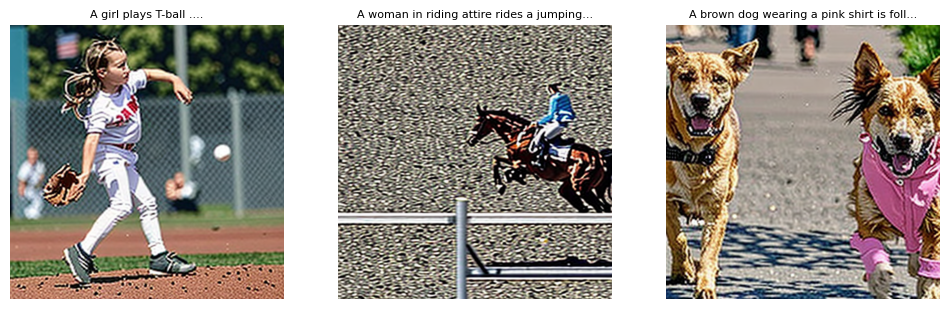

In [9]:
# Generating 
import matplotlib.pyplot as plt

images = [
    pipe(prompt=c, num_interference_steps=4, guidance_scale=0.0).images[0]
    for c in sample_captions
]

fig, axes = plt.subplots(1,3, figsize=(12,4))
for i, (img,cap) in enumerate(zip(images, sample_captions)):
    axes[i].imshow(img)
    axes[i].set_title(cap[:40] + "...", fontsize=8)
    axes[i].axis("off")
plt.show()